# ThyroVision: Uncertainty-Aware Morphological Reliability Assessment
### Complete Google Colab research notebook

**Goal:** train/evaluate a U-Net baseline, estimate predictive uncertainty with Monte Carlo Dropout, propagate uncertainty into morphological measurements, and produce reproducible tables/figures for research analysis.

**Important research safeguards**
- Use a patient-level official split if the dataset provides one. Random image-level splitting is only a fallback and must be disclosed.
- This notebook does not predict cancer or malignancy. Morphology descriptors are not clinical diagnoses.
- The original TRFE-Net paper reports Dice 81.26% and IoU 68.44%; this notebook's U-Net is a baseline, not a reproduction of TRFE-Net.
- Uncertainty is not automatically calibrated. The notebook measures association with feature error; do not claim clinical reliability without validation.

## 0. Runtime setup
In Colab select **Runtime → Change runtime type → T4 GPU** (if available).

In [1]:
import os, sys, json, random, zipfile, shutil, math, time, glob, re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from tqdm.auto import tqdm

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    import torch
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

import torch
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA: True


## 1. Install dependencies

In [2]:
!pip -q install scikit-image scipy scikit-learn seaborn

## 2. Get the TN3K dataset

Choose **one** method. The default uses Kaggle API. Upload your `kaggle.json` when prompted, or set `DATA_ROOT` manually if you already mounted/extracted the dataset.

If Kaggle access is unavailable, download the dataset ZIP from your Kaggle page and upload it using the alternative cell.

In [4]:
!rm -f /root/.kaggle/kaggle.json
!rm -f /root/.config/kaggle/kaggle.json


In [5]:
# ============================================================
# DATASET DOWNLOAD USING KAGGLEHUB
# ============================================================

!pip -q install kagglehub

import kagglehub
from pathlib import Path

KAGGLE_DATASET = "snehadeepika18/thyrovision-tn3k"

print("Downloading ThyroVision TN3K dataset...")
path = kagglehub.dataset_download(KAGGLE_DATASET)

DATA_ROOT = Path(path)

print("\nDataset downloaded successfully!")
print("Dataset location:", DATA_ROOT)


100%|██████████| 378M/378M [00:02<00:00, 137MB/s] 

Extracting files...



Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1


In [ ]:
# OPTION B: Google Drive (run only if needed)
# from google.colab import drive
# drive.mount('/content/drive')
# DATA_ROOT = '/content/drive/MyDrive/path/to/extracted/TN3K'

## 3. Inspect and configure image/mask discovery
The cell lists folders and common image files. Review the output. If automatic pairing fails, edit `IMAGE_DIR`, `MASK_DIR`, and the pairing function.

In [6]:
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
all_files = [p for p in Path(DATA_ROOT).rglob("*") if p.is_file()]
print("Files found:", len(all_files))
for p in all_files[:60]: print(p.relative_to(DATA_ROOT))

Files found: 17991
Thyroid Dataset/DDTI dataset/DDTI.pdf
Thyroid Dataset/DDTI dataset/readme.txt
Thyroid Dataset/tn3k/tn3k-trainval-fold4.json
Thyroid Dataset/tn3k/tn3k-trainval-fold0.json
Thyroid Dataset/tn3k/tn3k-trainval-fold1.json
Thyroid Dataset/tn3k/tn3k-trainval-fold3.json
Thyroid Dataset/tn3k/tn3k-trainval-fold2.json
Thyroid Dataset/tg3k/tg3k-trainval.json
Thyroid Dataset/tg3k/thyroid-image/0623.jpg
Thyroid Dataset/tg3k/thyroid-image/0634.jpg
Thyroid Dataset/tg3k/thyroid-image/2622.jpg
Thyroid Dataset/tg3k/thyroid-image/1594.jpg
Thyroid Dataset/tg3k/thyroid-image/2394.jpg
Thyroid Dataset/tg3k/thyroid-image/3171.jpg
Thyroid Dataset/tg3k/thyroid-image/1256.jpg
Thyroid Dataset/tg3k/thyroid-image/2291.jpg
Thyroid Dataset/tg3k/thyroid-image/3047.jpg
Thyroid Dataset/tg3k/thyroid-image/1633.jpg
Thyroid Dataset/tg3k/thyroid-image/1080.jpg
Thyroid Dataset/tg3k/thyroid-image/0810.jpg
Thyroid Dataset/tg3k/thyroid-image/3467.jpg
Thyroid Dataset/tg3k/thyroid-image/0718.jpg
Thyroid Dataset/t

In [7]:
# AUTO-DETECT candidate image and mask folders using folder names.
dirs = [p for p in Path(DATA_ROOT).rglob("*") if p.is_dir()]
for p in dirs:
    n = p.name.lower()
    if any(k in n for k in ["image", "img", "mask", "label", "gt", "annotation"]):
        count = sum(1 for f in p.iterdir() if f.is_file() and f.suffix.lower() in IMAGE_EXTS)
        if count: print(count, p)

# EDIT THESE if auto-detection is not correct.
IMAGE_DIR = None  # e.g. "/content/thyrovision_data/images"
MASK_DIR  = None  # e.g. "/content/thyrovision_data/masks"

# Pairing rule: same relative filename stem; common suffix variants are normalized.
def norm_stem(p):
    s = p.stem.lower()
    s = re.sub(r'(_mask|_label|_segmentation|_gt|_annotation)$', '', s)
    return s

def collect_images(folder):
    return [p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]

if IMAGE_DIR is None or MASK_DIR is None:
    # Heuristic only; inspect candidates above and set explicit paths if needed.
    candidates = [p for p in dirs if any(k in p.name.lower() for k in ["image","img","mask","label","gt"])]
    image_candidates = [p for p in candidates if any(k in p.name.lower() for k in ["image","img"])]
    mask_candidates = [p for p in candidates if any(k in p.name.lower() for k in ["mask","label","gt"])]
    if image_candidates and mask_candidates:
        IMAGE_DIR, MASK_DIR = str(image_candidates[0]), str(mask_candidates[0])
    else:
        raise RuntimeError("Could not infer image/mask folders. Set IMAGE_DIR and MASK_DIR manually.")
print("IMAGE_DIR:", IMAGE_DIR)
print("MASK_DIR:", MASK_DIR)

imgs, masks = collect_images(IMAGE_DIR), collect_images(MASK_DIR)
mask_map = {}
for p in masks: mask_map.setdefault(norm_stem(p), []).append(p)
pairs=[]
for im in imgs:
    key=norm_stem(im)
    if key in mask_map:
        # if duplicate normalized stems, prefer exact stem match
        choices=mask_map[key]
        exact=[m for m in choices if m.stem.lower()==im.stem.lower()]
        pairs.append((im, exact[0] if exact else choices[0]))
print("Image files:", len(imgs), "Mask files:", len(masks), "Paired:", len(pairs))
if not pairs: raise RuntimeError("No pairs found. Adjust pairing function or directories.")
print("Examples:", [(str(a),str(b)) for a,b in pairs[:5]])

614 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/test-image
2879 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/trainval-mask
614 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/test-mask
2879 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/trainval-image
3585 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tg3k/thyroid-image
3585 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tg3k/thyroid-mask
637 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/DDTI dataset/DDTI/1_or_data/mask
637 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/DDTI dataset/DDTI/1_or_data/image
637 /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision

## 4. Visual data quality check

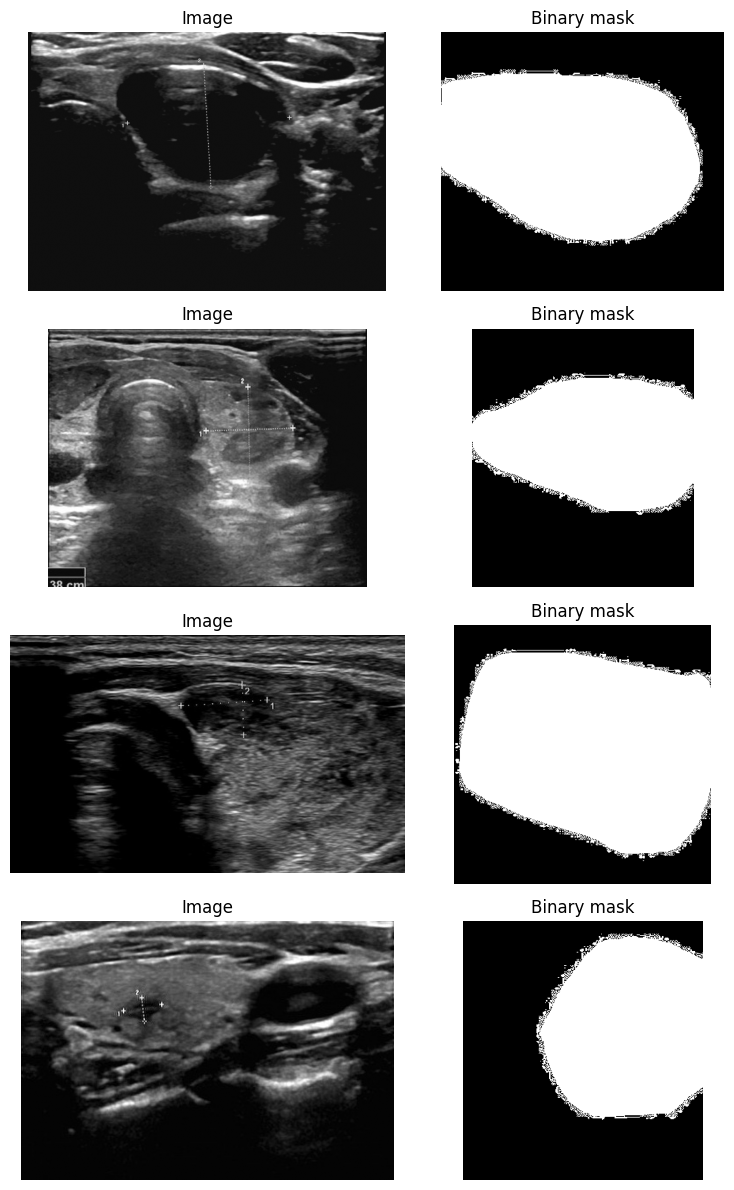

In [8]:
def read_gray(path):
    arr = np.array(Image.open(path).convert("L"))
    return arr
def read_mask(path):
    arr = np.array(Image.open(path).convert("L"))
    return (arr > 0).astype(np.uint8)

fig, axes = plt.subplots(min(4,len(pairs)), 2, figsize=(8, 3*min(4,len(pairs))))
if len(pairs)==1: axes=np.array([axes])
for i,(ip,mp) in enumerate(pairs[:4]):
    axes[i,0].imshow(read_gray(ip), cmap="gray"); axes[i,0].set_title("Image")
    axes[i,1].imshow(read_mask(mp), cmap="gray"); axes[i,1].set_title("Binary mask")
    axes[i,0].axis("off"); axes[i,1].axis("off")
plt.tight_layout()

## 5. Split data

**Preferred:** provide official train/validation/test directories or patient IDs and replace this split cell. The automatic fallback below is a reproducible image-level split, not patient-level. If multiple frames/images belong to the same patient, leakage may inflate test performance.

For now the fallback is 80/10/10. The split manifest is saved for reproducibility.

In [13]:
from pathlib import Path

print("DATA_ROOT =", DATA_ROOT)

root = Path(DATA_ROOT)

print("\nDoes DATA_ROOT exist?", root.exists())

if root.exists():
    files = [f for f in root.rglob("*") if f.is_file()]
    print("Total files found:", len(files))

    print("\nFirst 30 files:")
    for f in files[:30]:
        print(f)


DATA_ROOT = /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1

Does DATA_ROOT exist? True
Total files found: 17991

First 30 files:
/root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/DDTI dataset/DDTI.pdf
/root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/DDTI dataset/readme.txt
/root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/tn3k-trainval-fold4.json
/root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/tn3k-trainval-fold0.json
/root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/tn3k-trainval-fold1.json
/root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/tn3k-trainval-fold3.json
/root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k/tn3k-trainval-fold2.json
/root/.cac

In [14]:
from pathlib import Path

tn3k_root = Path(DATA_ROOT) / "Thyroid Dataset" / "tn3k"

print("TN3K folder:", tn3k_root)
print("Exists:", tn3k_root.exists())

# Find all image files inside TN3K
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

tn3k_images = [
    f for f in tn3k_root.rglob("*")
    if f.is_file() and f.suffix.lower() in image_exts
]

# Find all JSON files
tn3k_json = [
    f for f in tn3k_root.rglob("*.json")
    if f.is_file()
]

print("\nTN3K image files:", len(tn3k_images))
print("TN3K JSON files:", len(tn3k_json))

print("\nTN3K folders:")
for item in tn3k_root.iterdir():
    print(" -", item.name)


TN3K folder: /root/.cache/kagglehub/datasets/snehadeepika18/thyrovision-tn3k/versions/1/Thyroid Dataset/tn3k
Exists: True

TN3K image files: 6986
TN3K JSON files: 5

TN3K folders:
 - test-image
 - tn3k-trainval-fold4.json
 - tn3k-trainval-fold0.json
 - trainval-mask
 - tn3k-trainval-fold1.json
 - tn3k-trainval-fold3.json
 - test-mask
 - tn3k-trainval-fold2.json
 - trainval-image


In [15]:
from pathlib import Path

tn3k_root = Path(DATA_ROOT) / "Thyroid Dataset" / "tn3k"

for folder_name in ["trainval-image", "trainval-mask", "test-image", "test-mask"]:
    folder = tn3k_root / folder_name

    files = [
        f for f in folder.rglob("*")
        if f.is_file()
    ]

    print(f"{folder_name}: {len(files)} files")

    # Show first 5 filenames
    for f in files[:5]:
        print("   ", f.name)

    print()


trainval-image: 2879 files
    0623.jpg
    0634.jpg
    2622.jpg
    1594.jpg
    2394.jpg

trainval-mask: 2879 files
    0623.jpg
    0634.jpg
    2622.jpg
    1594.jpg
    2394.jpg

test-image: 614 files
    0262.jpg
    0257.jpg
    0073.jpg
    0091.jpg
    0286.jpg

test-mask: 614 files
    0262.jpg
    0257.jpg
    0073.jpg
    0091.jpg
    0286.jpg



In [16]:
from pathlib import Path

tn3k_root = Path(DATA_ROOT) / "Thyroid Dataset" / "tn3k"

trainval_image_dir = tn3k_root / "trainval-image"
trainval_mask_dir  = tn3k_root / "trainval-mask"

test_image_dir = tn3k_root / "test-image"
test_mask_dir  = tn3k_root / "test-mask"


def make_pairs(image_dir, mask_dir):
    image_map = {
        f.stem: f
        for f in image_dir.iterdir()
        if f.is_file()
    }

    mask_map = {
        f.stem: f
        for f in mask_dir.iterdir()
        if f.is_file()
    }

    common_keys = sorted(set(image_map) & set(mask_map))

    pairs = [
        (image_map[k], mask_map[k])
        for k in common_keys
    ]

    missing_masks = sorted(set(image_map) - set(mask_map))
    missing_images = sorted(set(mask_map) - set(image_map))

    return pairs, missing_masks, missing_images


trainval_pairs, missing_trainval_masks, missing_trainval_images = make_pairs(
    trainval_image_dir,
    trainval_mask_dir
)

test_pairs, missing_test_masks, missing_test_images = make_pairs(
    test_image_dir,
    test_mask_dir
)


print("Train/validation pairs:", len(trainval_pairs))
print("Test pairs:", len(test_pairs))

print("\nMissing trainval masks:", len(missing_trainval_masks))
print("Missing trainval images:", len(missing_trainval_images))

print("Missing test masks:", len(missing_test_masks))
print("Missing test images:", len(missing_test_images))

print("\nTOTAL paired images:", len(trainval_pairs) + len(test_pairs))


Train/validation pairs: 2879
Test pairs: 614

Missing trainval masks: 0
Missing trainval images: 0
Missing test masks: 0
Missing test images: 0

TOTAL paired images: 3493


In [17]:
from sklearn.model_selection import train_test_split
import os
import json

# ------------------------------------------------------------
# Build records
# ------------------------------------------------------------

def norm_stem(path):
    return Path(path).stem.lower().strip()


trainval_records = [
    {
        "image": str(img),
        "mask": str(mask),
        "key": norm_stem(img)
    }
    for img, mask in trainval_pairs
]

test_records = [
    {
        "image": str(img),
        "mask": str(mask),
        "key": norm_stem(img)
    }
    for img, mask in test_pairs
]


# ------------------------------------------------------------
# Split ONLY the official trainval set
# 90% training / 10% validation
# ------------------------------------------------------------

train_records, val_records = train_test_split(
    trainval_records,
    test_size=0.10,
    random_state=SEED
)


# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print("Train:", len(train_records))
print("Validation:", len(val_records))
print("Test:", len(test_records))
print("TOTAL:", len(train_records) + len(val_records) + len(test_records))


# ------------------------------------------------------------
# Save split manifest
# ------------------------------------------------------------

output_dir = "/content/thyrovision_outputs"
os.makedirs(output_dir, exist_ok=True)

split_manifest = {
    "split_type": "official TN3K trainval/test split; trainval randomly split into train/validation",
    "seed": SEED,
    "train": train_records,
    "validation": val_records,
    "test": test_records
}

with open(
    os.path.join(output_dir, "split_manifest.json"),
    "w"
) as f:
    json.dump(split_manifest, f, indent=2)

print("\nSaved:")
print(os.path.join(output_dir, "split_manifest.json"))


Train: 2591
Validation: 288
Test: 614
TOTAL: 3493

Saved:
/content/thyrovision_outputs/split_manifest.json


In [18]:
# ============================================================
# CHECK FOR DATA LEAKAGE BETWEEN SPLITS
# ============================================================

train_keys = {r["key"] for r in train_records}
val_keys   = {r["key"] for r in val_records}
test_keys  = {r["key"] for r in test_records}

print("Train images:", len(train_keys))
print("Validation images:", len(val_keys))
print("Test images:", len(test_keys))

print("\nTrain ∩ Validation:", len(train_keys & val_keys))
print("Train ∩ Test:", len(train_keys & test_keys))
print("Validation ∩ Test:", len(val_keys & test_keys))

if not (train_keys & val_keys or train_keys & test_keys or val_keys & test_keys):
    print("\n✅ No image-level overlap detected. Splits are clean.")
else:
    print("\n⚠️ OVERLAP DETECTED — do not continue yet.")


Train images: 2591
Validation images: 288
Test images: 614

Train ∩ Validation: 0
Train ∩ Test: 552
Validation ∩ Test: 62

⚠️ OVERLAP DETECTED — do not continue yet.


In [19]:
# ============================================================
# FIX SPLIT KEYS
# Use the relative path within the TN3K dataset so that
# trainval/ and test images remain distinct.
# ============================================================

def make_unique_key(path):
    return str(Path(path).relative_to(tn3k_root)).replace("\\", "/").lower()


# Rebuild records with folder-aware keys
trainval_records = [
    {
        "image": str(img),
        "mask": str(mask),
        "key": make_unique_key(img)
    }
    for img, mask in trainval_pairs
]

test_records = [
    {
        "image": str(img),
        "mask": str(mask),
        "key": make_unique_key(img)
    }
    for img, mask in test_pairs
]


# Recreate the same train/validation split
train_records, val_records = train_test_split(
    trainval_records,
    test_size=0.10,
    random_state=SEED
)


# Check overlap again
train_keys = {r["key"] for r in train_records}
val_keys   = {r["key"] for r in val_records}
test_keys  = {r["key"] for r in test_records}

print("Train:", len(train_records))
print("Validation:", len(val_records))
print("Test:", len(test_records))

print("\nTrain ∩ Validation:", len(train_keys & val_keys))
print("Train ∩ Test:", len(train_keys & test_keys))
print("Validation ∩ Test:", len(val_keys & test_keys))

if not (train_keys & val_keys or train_keys & test_keys or val_keys & test_keys):
    print("\n✅ No overlap detected. Splits are clean.")
else:
    print("\n⚠️ OVERLAP STILL DETECTED.")


Train: 2591
Validation: 288
Test: 614

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

✅ No overlap detected. Splits are clean.


## 6. Preprocessing and PyTorch Dataset

In [20]:
IMG_SIZE = 256
USE_CLAHE = True
USE_MEDIAN_FILTER = True

def preprocess_image(arr):
    arr = cv2.resize(arr, (IMG_SIZE,IMG_SIZE), interpolation=cv2.INTER_AREA)
    if USE_MEDIAN_FILTER: arr = cv2.medianBlur(arr, 3)
    if USE_CLAHE:
        arr = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(arr)
    return arr

def preprocess_mask(arr):
    return cv2.resize(arr.astype(np.uint8), (IMG_SIZE,IMG_SIZE), interpolation=cv2.INTER_NEAREST)

from torch.utils.data import Dataset, DataLoader
class TN3KDataset(Dataset):
    def __init__(self, records, augment=False):
        self.records=records; self.augment=augment
    def __len__(self): return len(self.records)
    def __getitem__(self, idx):
        r=self.records[idx]
        x=preprocess_image(read_gray(r["image"]))
        y=preprocess_mask(read_mask(r["mask"]))
        if self.augment:
            if random.random()<0.5: x=np.fliplr(x).copy(); y=np.fliplr(y).copy()
            if random.random()<0.5: x=np.flipud(x).copy(); y=np.flipud(y).copy()
            if random.random()<0.5:
                k=random.randint(0,3); x=np.rot90(x,k).copy(); y=np.rot90(y,k).copy()
        x=torch.from_numpy(x.astype(np.float32)/255.).unsqueeze(0)
        y=torch.from_numpy(y.astype(np.float32)).unsqueeze(0)
        return x,y,r["image"]

BATCH_SIZE=16
train_ds=TN3KDataset(train_records,True); val_ds=TN3KDataset(val_records); test_ds=TN3KDataset(test_records)
train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=2,pin_memory=True)
val_loader=DataLoader(val_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True)
test_loader=DataLoader(test_ds,batch_size=BATCH_SIZE,shuffle=False,num_workers=2,pin_memory=True)

## 7. U-Net with dropout for Monte Carlo inference

In [21]:
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        layers=[nn.Conv2d(in_ch,out_ch,3,padding=1,bias=False),nn.BatchNorm2d(out_ch),nn.ReLU(inplace=True),
                nn.Conv2d(out_ch,out_ch,3,padding=1,bias=False),nn.BatchNorm2d(out_ch),nn.ReLU(inplace=True)]
        if dropout>0: layers.append(nn.Dropout2d(dropout))
        self.net=nn.Sequential(*layers)
    def forward(self,x): return self.net(x)

class UNetMC(nn.Module):
    def __init__(self, dropout=0.15):
        super().__init__()
        self.d1=DoubleConv(1,32,dropout); self.d2=DoubleConv(32,64,dropout)
        self.d3=DoubleConv(64,128,dropout); self.d4=DoubleConv(128,256,dropout)
        self.bridge=DoubleConv(256,512,dropout)
        self.pool=nn.MaxPool2d(2)
        self.u4=nn.ConvTranspose2d(512,256,2,2); self.c4=DoubleConv(512,256,dropout)
        self.u3=nn.ConvTranspose2d(256,128,2,2); self.c3=DoubleConv(256,128,dropout)
        self.u2=nn.ConvTranspose2d(128,64,2,2); self.c2=DoubleConv(128,64,dropout)
        self.u1=nn.ConvTranspose2d(64,32,2,2); self.c1=DoubleConv(64,32,dropout)
        self.out=nn.Conv2d(32,1,1)
    def forward(self,x):
        a=self.d1(x); b=self.d2(self.pool(a)); c=self.d3(self.pool(b)); d=self.d4(self.pool(c))
        z=self.bridge(self.pool(d))
        z=self.c4(torch.cat([self.u4(z),d],1)); z=self.c3(torch.cat([self.u3(z),c],1))
        z=self.c2(torch.cat([self.u2(z),b],1)); z=self.c1(torch.cat([self.u1(z),a],1))
        return self.out(z)

model=UNetMC().to(DEVICE)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 7762465


## 8. Loss, metrics and training

In [23]:
print("BATCH_SIZE =", BATCH_SIZE)
print("Train batches =", len(train_loader))
print("Validation batches =", len(val_loader))
print("Test batches =", len(test_loader))

print("\nDataLoader workers:")
print("Train:", train_loader.num_workers)
print("Validation:", val_loader.num_workers)
print("Test:", test_loader.num_workers)


BATCH_SIZE = 16
Train batches = 162
Validation batches = 18
Test batches = 39

DataLoader workers:
Train: 2
Validation: 2
Test: 2


In [24]:
from pathlib import Path

print("Checkpoint/model files currently found:")

for p in Path("/content").rglob("*"):
    if p.is_file() and p.suffix.lower() in {".pth", ".pt", ".ckpt"}:
        print(p)


Checkpoint/model files currently found:
/content/thyrovision_outputs/best_unet_mc.pth


In [25]:
def dice_bce_loss(logits, targets, smooth=1.0):
    probs=torch.sigmoid(logits)
    inter=(probs*targets).sum(dim=(1,2,3))
    denom=probs.sum(dim=(1,2,3))+targets.sum(dim=(1,2,3))
    dice=(2*inter+smooth)/(denom+smooth)
    return F.binary_cross_entropy_with_logits(logits,targets) + (1-dice).mean()

@torch.no_grad()
def batch_metrics(logits, y, threshold=0.5):
    p=(torch.sigmoid(logits)>threshold).float()
    dims=(1,2,3); inter=(p*y).sum(dims); ps=p.sum(dims); ys=y.sum(dims)
    dice=(2*inter+1e-7)/(ps+ys+1e-7)
    iou=(inter+1e-7)/(ps+ys-inter+1e-7)
    return dice.mean().item(), iou.mean().item()

def evaluate(model, loader):
    model.eval(); losses=[]; dices=[]; ious=[]
    with torch.no_grad():
        for x,y,_ in loader:
            x=x.to(DEVICE); y=y.to(DEVICE); logits=model(x)
            losses.append(dice_bce_loss(logits,y).item())
            d,i=batch_metrics(logits,y); dices.append(d); ious.append(i)
    return np.mean(losses),np.mean(dices),np.mean(ious)

EPOCHS=40
LR=1e-3
PATIENCE=8
optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="max",factor=0.5,patience=3)
best_dice=-1; wait=0
history=[]
MODEL_PATH="/content/thyrovision_outputs/best_unet_mc.pth"
for epoch in range(1,EPOCHS+1):
    model.train(); tr_losses=[]
    for x,y,_ in tqdm(train_loader,leave=False):
        x=x.to(DEVICE); y=y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss=dice_bce_loss(model(x),y); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        optimizer.step(); tr_losses.append(loss.item())
    vl,vd,vi=evaluate(model,val_loader); scheduler.step(vd)
    history.append({"epoch":epoch,"train_loss":np.mean(tr_losses),"val_loss":vl,"val_dice":vd,"val_iou":vi,
                    "lr":optimizer.param_groups[0]["lr"]})
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {np.mean(tr_losses):.4f} | val Dice {vd:.4f} | IoU {vi:.4f}")
    if vd>best_dice:
        best_dice=vd; wait=0
        torch.save({"model_state":model.state_dict(),"epoch":epoch,"best_val_dice":best_dice},MODEL_PATH)
    else:
        wait+=1
        if wait>=PATIENCE: print("Early stopping"); break
pd.DataFrame(history).to_csv("/content/thyrovision_outputs/training_history.csv",index=False)
ckpt=torch.load(MODEL_PATH,map_location=DEVICE)
model.load_state_dict(ckpt["model_state"])
print("Best epoch:",ckpt["epoch"],"Best validation Dice:",ckpt["best_val_dice"])

  0%|          | 0/162 [00:00<?, ?it/s]

Epoch 01/40 | train loss 0.8726 | val Dice 0.5414 | IoU 0.4056


  0%|          | 0/162 [00:00<?, ?it/s]

Epoch 02/40 | train loss 0.8419 | val Dice 0.5660 | IoU 0.4307


  0%|          | 0/162 [00:00<?, ?it/s]

...

  0%|          | 0/162 [00:00<?, ?it/s]

Epoch 39/40 | train loss 0.4727 | val Dice 0.7598 | IoU 0.6439


  0%|          | 0/162 [00:00<?, ?it/s]

Epoch 40/40 | train loss 0.4669 | val Dice 0.7592 | IoU 0.6446


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

In [26]:
# Reload the trusted checkpoint created by this notebook.
# PyTorch 2.6+ defaults to weights_only=True, which rejects this
# checkpoint because it contains additional training metadata.

MODEL_PATH = "/content/thyrovision_outputs/best_unet_mc.pth"

ckpt = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state"])

print("Checkpoint loaded successfully.")
print("Best epoch:", ckpt["epoch"])
print("Best validation Dice:", ckpt["best_val_dice"])
print("Checkpoint:", MODEL_PATH)


Checkpoint loaded successfully.
Best epoch: 39
Best validation Dice: 0.7598085370328691
Checkpoint: /content/thyrovision_outputs/best_unet_mc.pth


## 9. Deterministic test evaluation
Report both image-wise mean and global pixel metrics. Do not compare numbers across papers unless split and evaluation protocol are aligned.

In [27]:
@torch.no_grad()
def deterministic_predictions(model, loader):
    model.eval(); rows=[]; outputs=[]
    for x,y,paths in tqdm(loader):
        x=x.to(DEVICE); logits=model(x); probs=torch.sigmoid(logits).cpu().numpy()
        ys=y.numpy()
        for j in range(len(paths)):
            p=(probs[j,0]>=0.5).astype(np.uint8); gt=ys[j,0].astype(np.uint8)
            inter=np.logical_and(p,gt).sum(); union=np.logical_or(p,gt).sum()
            dice=(2*inter+1e-7)/(p.sum()+gt.sum()+1e-7); iou=(inter+1e-7)/(union+1e-7)
            rows.append({"image":paths[j],"dice":dice,"iou":iou,
                         "precision":(inter+1e-7)/(p.sum()+1e-7),
                         "recall":(inter+1e-7)/(gt.sum()+1e-7)})
            outputs.append((x[j].cpu().numpy()[0],gt,p,probs[j,0]))
    return pd.DataFrame(rows),outputs

test_metrics, test_outputs=deterministic_predictions(model,test_loader)
test_metrics.to_csv("/content/thyrovision_outputs/test_image_metrics.csv",index=False)
print(test_metrics[["dice","iou","precision","recall"]].agg(["mean","std"]).to_string())
print("Global Dice/IoU:",
      2*sum(np.logical_and(o[1],o[2]).sum() for o in test_outputs)/(sum(o[1].sum()+o[2].sum() for o in test_outputs)+1e-7),
      sum(np.logical_and(o[1],o[2]).sum() for o in test_outputs)/(sum(np.logical_or(o[1],o[2]).sum() for o in test_outputs)+1e-7))

  0%|          | 0/39 [00:00<?, ?it/s]

          dice       iou  precision    recall
mean  0.765197  0.661011   0.793343  0.811027
std   0.223073  0.233483   0.222332  0.242542
Global Dice/IoU: 0.8334300856466327 0.7144278927410924


## 10. Monte Carlo Dropout inference
Only dropout layers are activated; batch normalization remains in evaluation mode. Increase `MC_PASSES` (e.g. 30–50) for final experiments if runtime permits.

In [28]:
def enable_dropout_only(m):
    for layer in m.modules():
        if isinstance(layer,(nn.Dropout,nn.Dropout2d,nn.Dropout3d)):
            layer.train()

@torch.no_grad()
def mc_predict_one(image_tensor, passes=30):
    # image_tensor: [1,1,H,W]
    model.eval(); enable_dropout_only(model)
    samples=[]
    for _ in range(passes):
        samples.append(torch.sigmoid(model(image_tensor.to(DEVICE))).cpu().numpy()[0,0])
    model.eval()
    arr=np.stack(samples,axis=0)
    mean=arr.mean(0)
    variance=arr.var(0)
    entropy=-(mean*np.log(mean+1e-8)+(1-mean)*np.log(1-mean+1e-8))
    return mean,variance,entropy,arr

MC_PASSES=30

## 11. Morphology and texture descriptors

In [29]:
from skimage.measure import label, regionprops, perimeter
from skimage.feature import graycomatrix, graycoprops
from scipy.ndimage import binary_fill_holes

def morphology_features(mask, gray=None):
    m=(mask>0).astype(np.uint8)
    if m.sum()==0:
        return {k:np.nan for k in ["area","perimeter","circularity","aspect_ratio","solidity","eccentricity","skeleton_length","branch_points","glcm_contrast","glcm_homogeneity","glcm_energy","glcm_correlation"]}
    lab=label(m); regions=regionprops(lab)
    reg=max(regions,key=lambda r:r.area)
    area=float(reg.area); per=float(perimeter(m, neighborhood=8))
    circularity=float(4*np.pi*area/(per**2+1e-8))
    minr,minc,maxr,maxc=reg.bbox
    aspect=float((maxc-minc)/(maxr-minr+1e-8))
    # skeleton descriptors
    from skimage.morphology import skeletonize
    sk=skeletonize(m>0); sklen=float(sk.sum())
    neigh=cv2.filter2D(sk.astype(np.uint8),-1,np.ones((3,3),np.uint8))
    # includes center; branch point approximated as >=4 neighboring skeleton pixels
    branches=float(((neigh>=4)&sk).sum())
    feats={"area":area,"perimeter":per,"circularity":circularity,"aspect_ratio":aspect,
           "solidity":float(reg.solidity),"eccentricity":float(reg.eccentricity),
           "skeleton_length":sklen,"branch_points":branches}
    if gray is not None:
        g=np.asarray(gray,dtype=np.uint8)
        roi=g[m>0]
        if roi.size:
            # quantize full grayscale to 32 levels and compute GLCM on masked bounding crop
            crop=g[minr:maxr,minc:maxc]
            mc=m[minr:maxr,minc:maxc]
            q=(crop//8).astype(np.uint8)
            # set outside mask to 0; texture computed in ROI bounding box, interpreted cautiously
            q[mc==0]=0
            gl=graycomatrix(q,distances=[1],angles=[0],levels=32,symmetric=True,normed=True)
            for prop in ["contrast","homogeneity","energy","correlation"]:
                feats["glcm_"+prop]=float(graycoprops(gl,prop)[0,0])
        else:
            for prop in ["contrast","homogeneity","energy","correlation"]: feats["glcm_"+prop]=np.nan
    else:
        for prop in ["contrast","homogeneity","energy","correlation"]: feats["glcm_"+prop]=np.nan
    return feats

## 12. Uncertainty propagation into morphology
For each test image, sample masks from MC probabilities. Use the mean probability threshold for the point estimate and the distribution across stochastic masks for feature uncertainty. This is an empirical variability estimate, not automatically a calibrated confidence interval.

In [30]:
def feature_uncertainty(mc_probs, gray, threshold=0.5):
    feature_rows=[]
    for prob in mc_probs:
        feature_rows.append(morphology_features((prob>=threshold).astype(np.uint8),gray))
    df=pd.DataFrame(feature_rows)
    result={}
    for col in df.columns:
        vals=df[col].replace([np.inf,-np.inf],np.nan).dropna().values
        result[col+"_mc_mean"]=float(np.mean(vals)) if len(vals) else np.nan
        result[col+"_mc_std"]=float(np.std(vals,ddof=1)) if len(vals)>1 else np.nan
        result[col+"_mc_q025"]=float(np.quantile(vals,.025)) if len(vals) else np.nan
        result[col+"_mc_q975"]=float(np.quantile(vals,.975)) if len(vals) else np.nan
    return result,df

all_rows=[]; visualization=[]
for idx,((gray,gt,pred,prob), rec) in enumerate(tqdm(zip(test_outputs,test_records),total=len(test_outputs))):
    xt=torch.from_numpy(gray).float()[None,None]
    mean,var,entropy,samples=mc_predict_one(xt,MC_PASSES)
    pred_mc=(mean>=0.5).astype(np.uint8)
    gt_feat=morphology_features(gt, (gray*255).astype(np.uint8))
    pred_feat=morphology_features(pred_mc,(gray*255).astype(np.uint8))
    mc_summary,mc_df=feature_uncertainty(samples,(gray*255).astype(np.uint8))
    # mean pixel variance over predicted foreground/boundary and whole image
    boundary=cv2.morphologyEx(pred_mc,cv2.MORPH_GRADIENT,np.ones((3,3),np.uint8))>0
    row={"image":rec["image"],"test_dice":test_metrics.iloc[idx]["dice"],"test_iou":test_metrics.iloc[idx]["iou"],
         "mean_pixel_variance":float(var.mean()),
         "foreground_uncertainty":float(var[pred_mc>0].mean()) if pred_mc.any() else np.nan,
         "boundary_uncertainty":float(var[boundary].mean()) if boundary.any() else np.nan,
         "mean_entropy":float(entropy.mean())}
    for k,v in gt_feat.items(): row["gt_"+k]=v
    for k,v in pred_feat.items(): row["pred_"+k]=v
    row.update(mc_summary)
    # absolute morphology measurement error vs GT mask descriptor
    for k in ["area","perimeter","circularity","aspect_ratio","solidity","eccentricity","skeleton_length","branch_points"]:
        row[k+"_abs_error"]=abs(row["pred_"+k]-row["gt_"+k]) if pd.notna(row["pred_"+k]) and pd.notna(row["gt_"+k]) else np.nan
        row[k+"_mc_std"]=row.get(k+"_mc_std",np.nan)
    all_rows.append(row)
    if idx<12: visualization.append((gray,gt,pred_mc,mean,var,entropy,rec["image"]))
unc_df=pd.DataFrame(all_rows)
unc_df.to_csv("/content/thyrovision_outputs/uncertainty_morphology_test.csv",index=False)
print("Saved",unc_df.shape,"table")
unc_df.head()

  0%|          | 0/614 [00:00<?, ?it/s]

Saved (614, 87) table


,image,test_dice,test_iou,mean_pixel_variance,foreground_uncertainty,boundary_uncertainty,mean_entropy,gt_area,gt_perimeter,gt_circularity,...,glcm_correlation_mc_q025,glcm_correlation_mc_q975,area_abs_error,perimeter_abs_error,circularity_abs_error,aspect_ratio_abs_error,solidity_abs_error,eccentricity_abs_error,skeleton_length_abs_error,branch_points_abs_error
0,/root/.cache/kagglehub/datasets/snehadeepika18...,0.865597,0.763042,0.000596,0.007704,0.050230,0.022409,2518.0,384.260931,0.214296,...,0.848554,0.873577,216.0,168.260931,0.405727,0.051801,0.107134,0.064496,585.0,268.0
1,/root/.cache/kagglehub/datasets/snehadeepika18...,0.939394,0.885714,0.001897,0.007935,0.041666,0.062121,5557.0,436.219300,0.366978,...,0.893371,0.918446,414.0,65.390873,0.178667,0.083801,0.027515,0.043737,514.0,148.0
2,/root/.cache/kagglehub/datasets/snehadeepika18...,0.891244,0.803823,0.003759,0.015575,0.051227,0.085444,7267.0,811.722871,0.138596,...,0.913382,0.945070,1107.0,227.480231,0.088184,0.041711,0.000373,0.007598,1224.0,442.0
3,/root/.cache/kagglehub/datasets/snehadeepika18...,0.618625,0.447833,0.009185,0.037827,0.061808,0.147419,5801.0,1229.534055,0.048220,...,0.881304,0.924015,2760.0,630.670094,0.058334,0.338377,0.171709,0.222292,1550.0,771.0
4,/root/.cache/kagglehub/datasets/snehadeepika18...,0.830108,0.709559,0.000498,0.006955,0.049038,0.026630,808.0,196.698485,0.262433,...,0.847051,0.876814,255.0,52.698485,0.381763,0.173950,0.149794,0.094602,191.0,105.0


## 13. Evaluate whether uncertainty tracks morphology error
Primary analysis: Spearman correlation between estimated feature variability and absolute feature error. Also report sample size and p-value. Correlation is association, not proof of calibration.

In [31]:
from scipy.stats import spearmanr, pearsonr
features=["area","perimeter","circularity","aspect_ratio","solidity","eccentricity","skeleton_length","branch_points"]
corr_rows=[]
for f in features:
    x=unc_df[f+"_mc_std"]; y=unc_df[f+"_abs_error"]
    valid=np.isfinite(x)&np.isfinite(y)
    if valid.sum()>=5:
        rho,pv=spearmanr(x[valid],y[valid])
        corr_rows.append({"feature":f,"n":int(valid.sum()),"spearman_rho":rho,"p_value":pv})
corr_df=pd.DataFrame(corr_rows)
corr_df.to_csv("/content/thyrovision_outputs/uncertainty_error_correlations.csv",index=False)
display(corr_df)

,feature,n,spearman_rho,p_value
0,area,605,0.623323,2.030409e-66
1,perimeter,605,0.021105,6.043900e-01
2,circularity,605,-0.158858,8.700250e-05
3,aspect_ratio,605,0.427984,2.424610e-28
4,solidity,605,0.011590,7.760316e-01
5,eccentricity,605,0.375113,1.192270e-21
6,skeleton_length,605,0.373088,2.038377e-21
7,branch_points,605,0.171439,2.239790e-05


## 14. Reliability-weighted morphology score (exploratory)
This section deliberately labels the score exploratory. The original hand-set score is not a validated clinical risk score. We compute a transparent irregularity descriptor from predicted morphology and report reliability separately; do not interpret it as malignancy.

In [32]:
# Feature transformations are descriptive and data-dependent.
# Fit min/max only on TRAIN masks in a future rigorous study; here use training-derived GT features.
def extract_feature_table(records):
    rows=[]
    for r in tqdm(records):
        g=preprocess_image(read_gray(r["image"]))
        m=preprocess_mask(read_mask(r["mask"]))
        rows.append(morphology_features(m,g))
    return pd.DataFrame(rows)

train_gt_features=extract_feature_table(train_records)
feature_cols=["circularity","solidity","eccentricity","branch_points","glcm_contrast"]
train_stats={}
for c in feature_cols:
    vals=train_gt_features[c].replace([np.inf,-np.inf],np.nan).dropna()
    train_stats[c]={"min":float(vals.min()),"max":float(vals.max())}
with open("/content/thyrovision_outputs/train_feature_scaling.json","w") as f: json.dump(train_stats,f,indent=2)

def scale01(v,c):
    lo,hi=train_stats[c]["min"],train_stats[c]["max"]
    if not np.isfinite(v): return np.nan
    return float(np.clip((v-lo)/(hi-lo+1e-8),0,1))

# Exploratory morphology irregularity: inverse circularity + inverse solidity + eccentricity + branch density proxy + contrast.
score=[]
for _,r in unc_df.iterrows():
    vals=[1-scale01(r["pred_circularity"],"circularity"),
          1-scale01(r["pred_solidity"],"solidity"),
          scale01(r["pred_eccentricity"],"eccentricity"),
          scale01(r["pred_branch_points"],"branch_points"),
          scale01(r["pred_glcm_contrast"],"glcm_contrast")]
    s=float(np.nanmean(vals))
    # normalized reliability proxy based on mean variance; not calibrated probability
    u=float(r["mean_pixel_variance"])
    score.append({"image":r["image"],"exploratory_irregularity_index":s,
                  "uncertainty_proxy":u,"reliability_proxy":1-u})
score_df=pd.DataFrame(score)
score_df.to_csv("/content/thyrovision_outputs/exploratory_irregularity_reliability.csv",index=False)
display(score_df.describe())

  0%|          | 0/2591 [00:00<?, ?it/s]

/tmp/ipykernel_3481/697359798.py:32: RuntimeWarning: Mean of empty slice
  s=float(np.nanmean(vals))


,exploratory_irregularity_index,uncertainty_proxy,reliability_proxy
count,605.000000,614.000000,614.000000
mean,0.191069,0.003282,0.996718
std,0.108163,0.003007,0.003007
min,0.016381,0.000056,0.980436
25%,0.114667,0.001090,0.995597
50%,0.156749,0.002341,0.997659
75%,0.250221,0.004403,0.998910
max,0.625309,0.019564,0.999944


## 15. Visualize predictions and uncertainty

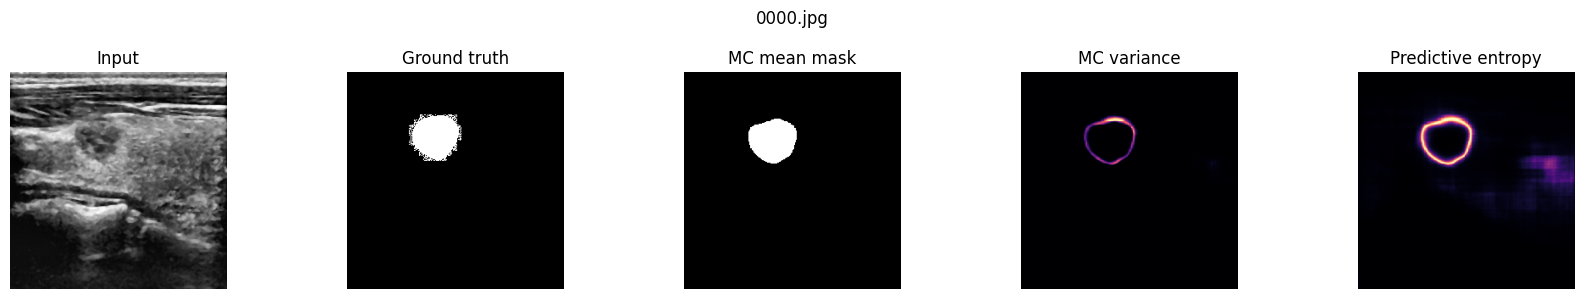

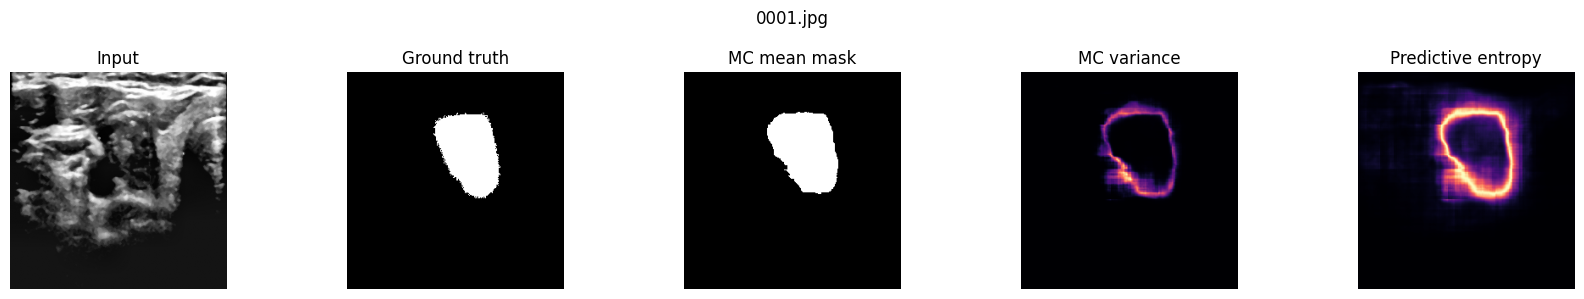

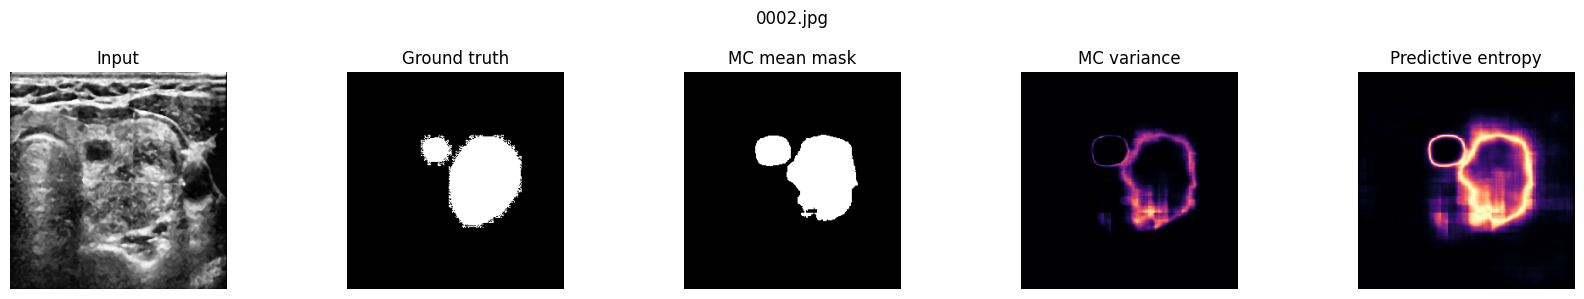

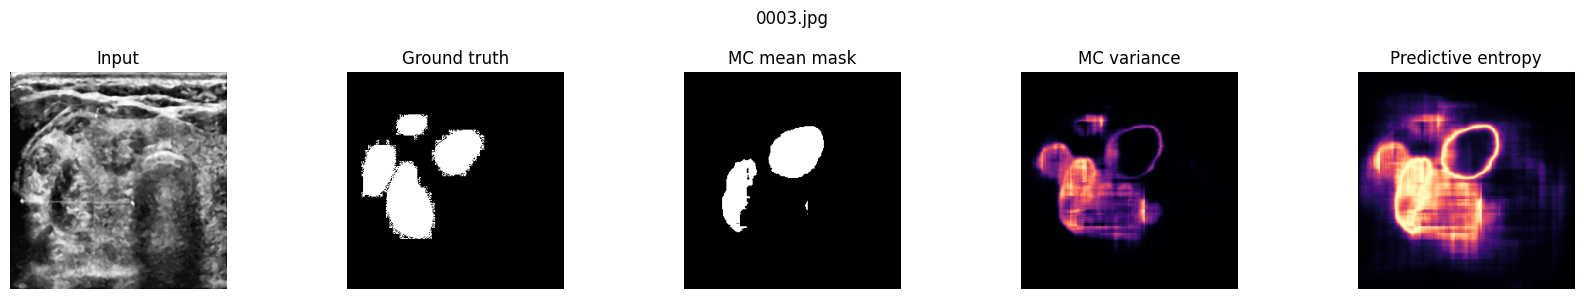

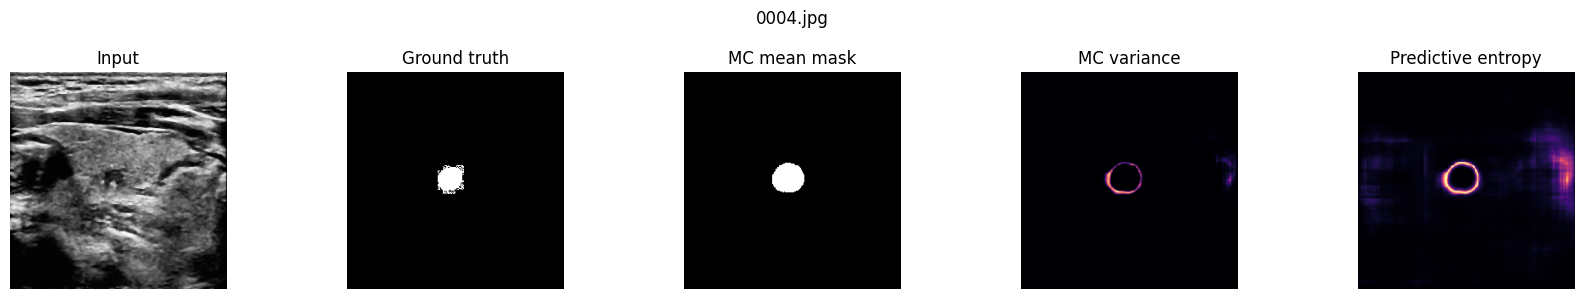

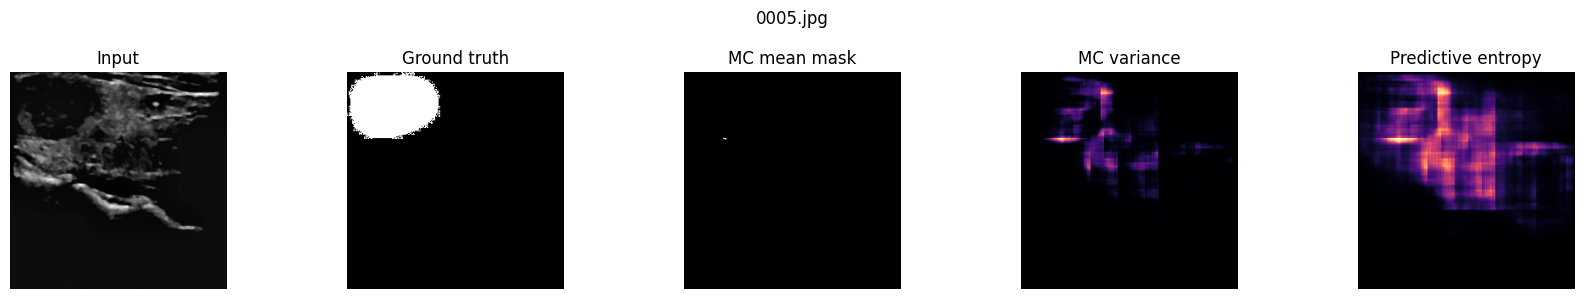

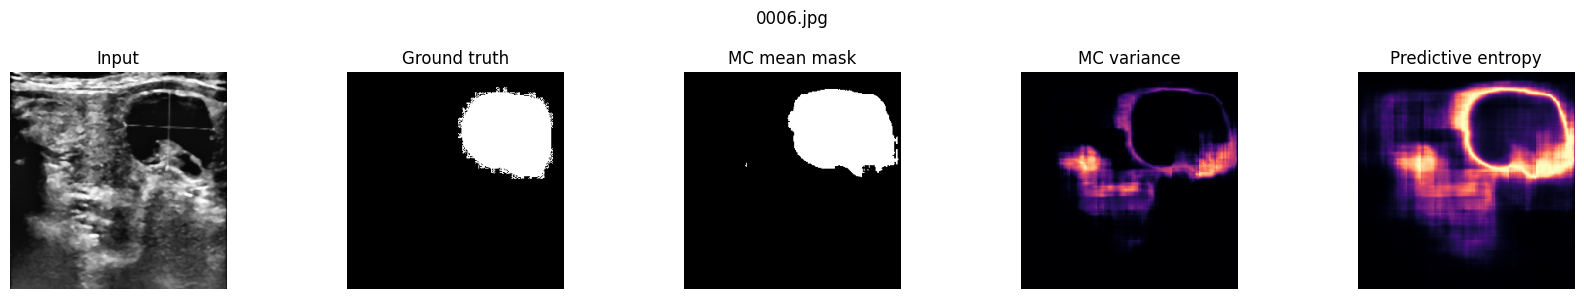

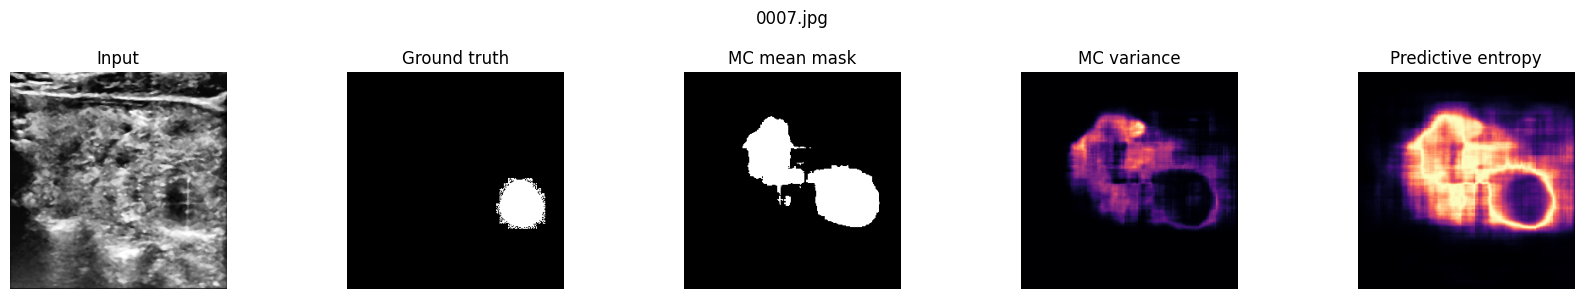

In [33]:
for gray,gt,pred,mean,var,entropy,path in visualization[:8]:
    fig,ax=plt.subplots(1,5,figsize=(17,3))
    ax[0].imshow(gray,cmap="gray"); ax[0].set_title("Input")
    ax[1].imshow(gt,cmap="gray"); ax[1].set_title("Ground truth")
    ax[2].imshow(pred,cmap="gray"); ax[2].set_title("MC mean mask")
    ax[3].imshow(var,cmap="magma"); ax[3].set_title("MC variance")
    ax[4].imshow(entropy,cmap="magma"); ax[4].set_title("Predictive entropy")
    for a in ax:a.axis("off")
    plt.suptitle(Path(path).name); plt.tight_layout(); plt.show()

## 16. Figures and summary metrics

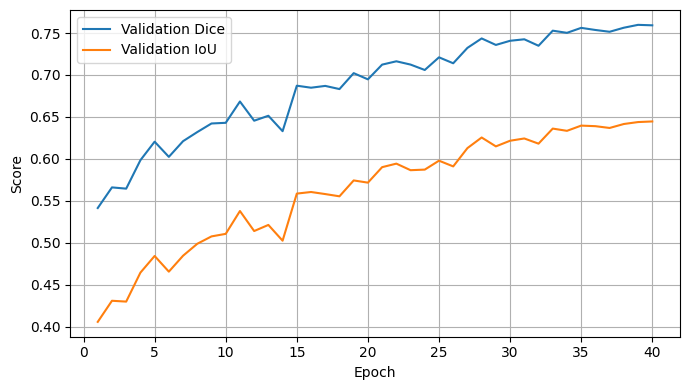

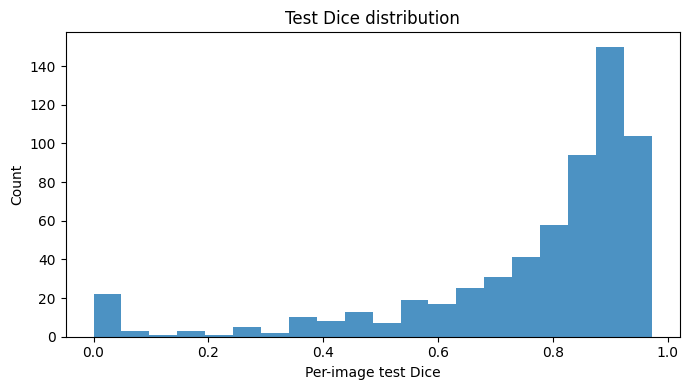

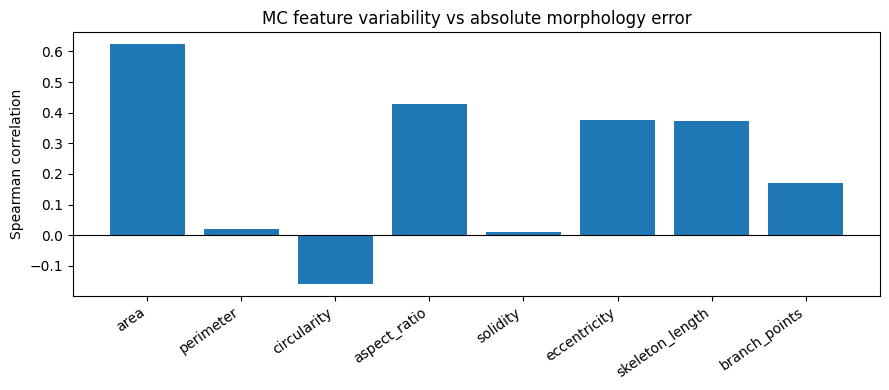

In [34]:
hist_df=pd.DataFrame(history)
plt.figure(figsize=(7,4)); plt.plot(hist_df.epoch,hist_df.val_dice,label="Validation Dice")
plt.plot(hist_df.epoch,hist_df.val_iou,label="Validation IoU")
plt.xlabel("Epoch"); plt.ylabel("Score"); plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig("/content/thyrovision_outputs/training_curves.png",dpi=200); plt.show()

plt.figure(figsize=(7,4))
plt.hist(test_metrics.dice,bins=20,alpha=.8)
plt.xlabel("Per-image test Dice"); plt.ylabel("Count"); plt.title("Test Dice distribution"); plt.tight_layout()
plt.savefig("/content/thyrovision_outputs/test_dice_distribution.png",dpi=200); plt.show()

if len(corr_df):
    plt.figure(figsize=(9,4))
    plt.bar(corr_df.feature,corr_df.spearman_rho)
    plt.axhline(0,color="black",linewidth=.8); plt.xticks(rotation=35,ha="right")
    plt.ylabel("Spearman correlation"); plt.title("MC feature variability vs absolute morphology error")
    plt.tight_layout(); plt.savefig("/content/thyrovision_outputs/uncertainty_error_correlation.png",dpi=200); plt.show()

## 17. Export a complete results package

In [35]:
# Summary includes split caveat, training setup, test metrics, correlation analysis.
summary={
 "project":"ThyroVision uncertainty-aware morphology reliability",
 "seed":SEED,"image_size":IMG_SIZE,"epochs_requested":EPOCHS,"epochs_completed":len(history),
 "best_epoch":int(ckpt["epoch"]),"best_validation_dice":float(ckpt["best_val_dice"]),
 "mc_passes":MC_PASSES,"test_n":int(len(test_metrics)),
 "test_dice_mean":float(test_metrics.dice.mean()),"test_dice_std":float(test_metrics.dice.std()),
 "test_iou_mean":float(test_metrics.iou.mean()),"test_iou_std":float(test_metrics.iou.std()),
 "test_precision_mean":float(test_metrics.precision.mean()),"test_recall_mean":float(test_metrics.recall.mean()),
 "split_warning":"Image-level random split fallback. Replace with patient-level/official split for final claims.",
 "clinical_warning":"Morphology index is exploratory and is not a malignancy or diagnostic score."
}
with open("/content/thyrovision_outputs/experiment_summary.json","w") as f: json.dump(summary,f,indent=2)
print(json.dumps(summary,indent=2))

{
  "project": "ThyroVision uncertainty-aware morphology reliability",
  "seed": 42,
  "image_size": 256,
  "epochs_requested": 40,
  "epochs_completed": 40,
  "best_epoch": 39,
  "best_validation_dice": 0.7598085370328691,
  "mc_passes": 30,
  "test_n": 614,
  "test_dice_mean": 0.76519669460188,
  "test_dice_std": 0.22307329334931256,
  "test_iou_mean": 0.6610111187481978,
  "test_iou_std": 0.23348325577780668,
  "test_precision_mean": 0.7933425324273102,
  "test_recall_mean": 0.8110267846818495,
  "split_warning": "Image-level random split fallback. Replace with patient-level/official split for final claims.",
  "clinical_warning": "Morphology index is exploratory and is not a malignancy or diagnostic score."
}


In [36]:
# Zip all outputs for sharing
OUT="/content/thyrovision_outputs"
zip_path="/content/ThyroVision_Research_Results.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in Path(OUT).rglob("*"):
        if p.is_file(): z.write(p,arcname=str(p.relative_to(OUT)))
print("Created:",zip_path, "Size MB:",round(os.path.getsize(zip_path)/1e6,2))
from google.colab import files
files.download(zip_path)

Created: /content/ThyroVision_Research_Results.zip Size MB: 29.55


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 18. What to send back for paper writing

Upload the downloaded `ThyroVision_Research_Results.zip` here. Also tell me:
1. Whether the dataset split was patient-level or image-level.
2. Whether the notebook ran on GPU and which GPU.
3. Any errors or cells you had to modify.

**Do not report the exploratory irregularity index as a clinical risk score.** The central hypothesis to test is whether MC feature variability is associated with the actual error in morphology measurements.

In [37]:
print("hello")

hello


In [38]:
# READ-ONLY analysis of saved results. This does NOT retrain or modify your project.
import os, glob, zipfile, json
from pathlib import Path

# Find a ZIP already in the runtime; otherwise upload it.
zip_candidates = glob.glob("/content/*.zip") + glob.glob("/mnt/data/*.zip")

if zip_candidates:
    ZIP_PATH = max(zip_candidates, key=os.path.getmtime)
    print("Using:", ZIP_PATH)
else:
    from google.colab import files
    uploaded = files.upload()
    ZIP_PATH = next((f"/content/{name}" for name in uploaded if name.lower().endswith(".zip")), None)
    if ZIP_PATH is None:
        raise FileNotFoundError("Please upload your ThyroVision results ZIP.")

OUT_DIR = "/content/thyrovision_paper_checks"
os.makedirs(OUT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(OUT_DIR)

print("Extracted saved results to:", OUT_DIR)
print("\nCSV files found:")
for p in glob.glob(OUT_DIR + "/**/*.csv", recursive=True):
    print("-", os.path.relpath(p, OUT_DIR))

Using: /content/ThyroVision_Research_Results.zip
Extracted saved results to: /content/thyrovision_paper_checks

CSV files found:
- test_image_metrics.csv
- exploratory_irregularity_reliability.csv
- uncertainty_morphology_test.csv
- uncertainty_error_correlations.csv
- training_history.csv


In [39]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from pathlib import Path

# Locate the saved uncertainty/morphology results.
csv_files = list(Path(OUT_DIR).rglob("*.csv"))

def find_csv(keyword):
    matches = [p for p in csv_files if keyword.lower() in p.name.lower()]
    if not matches:
        raise FileNotFoundError(f"Could not find a CSV containing: {keyword}")
    return pd.read_csv(matches[0])

df = find_csv("uncertainty_morphology_test")
print("Loaded:", len(df), "test rows")
print("Columns:\n", "\n".join(df.columns))

# Feature names as stored in the results.
features = [
    "area", "perimeter", "circularity", "aspect_ratio",
    "solidity", "eccentricity", "skeleton_length", "branch_points"
]

coverage_rows = []
for f in features:
    gt_col = f"gt_{f}"
    lo_col = f"{f}_mc_q025"
    hi_col = f"{f}_mc_q975"

    if not all(c in df.columns for c in [gt_col, lo_col, hi_col]):
        print(f"Skipping {f}: required columns not found.")
        continue

    valid = df[[gt_col, lo_col, hi_col]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(valid) == 0:
        continue

    covered = (valid[gt_col] >= valid[lo_col]) & (valid[gt_col] <= valid[hi_col])
    width = valid[hi_col] - valid[lo_col]

    coverage_rows.append({
        "feature": f,
        "n": len(valid),
        "empirical_coverage": covered.mean(),
        "mean_interval_width": width.mean(),
        "median_interval_width": width.median()
    })

coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df.round(4))
coverage_df.to_csv(f"{OUT_DIR}/interval_coverage_width.csv", index=False)

# Count test cases with zero Dice and missing predicted morphology.
failure_summary = {}
if "test_dice" in df.columns:
    failure_summary["zero_dice_cases"] = int((df["test_dice"].fillna(0) == 0).sum())
    failure_summary["test_cases"] = int(len(df))

pred_feature_cols = [c for c in df.columns if c.startswith("pred_")]
if pred_feature_cols:
    failure_summary["rows_with_all_pred_features_missing"] = int(
        df[pred_feature_cols].isna().all(axis=1).sum()
    )

print("\nFailure-case summary:")
print(failure_summary)

# Correlate uncertainty measures with segmentation error.
seg_rows = []
if "test_dice" in df.columns:
    df["dice_error"] = 1 - df["test_dice"]

if "test_iou" in df.columns:
    df["iou_error"] = 1 - df["test_iou"]

uncertainty_cols = ["mean_pixel_variance", "boundary_uncertainty", "mean_entropy"]
error_cols = ["dice_error", "iou_error"]

for u in uncertainty_cols:
    if u not in df.columns:
        continue
    for e in error_cols:
        if e not in df.columns:
            continue
        valid = df[[u, e]].replace([np.inf, -np.inf], np.nan).dropna()
        if len(valid) < 3:
            continue
        rho, p = spearmanr(valid[u], valid[e])
        seg_rows.append({
            "uncertainty_measure": u,
            "segmentation_error": e,
            "n": len(valid),
            "spearman_rho": rho,
            "p_value": p
        })

seg_corr_df = pd.DataFrame(seg_rows)
print("\nUncertainty vs segmentation error:")
display(seg_corr_df.round(5))
seg_corr_df.to_csv(f"{OUT_DIR}/uncertainty_segmentation_error_correlations.csv", index=False)

Loaded: 614 test rows
Columns:
 image
test_dice
test_iou
mean_pixel_variance
foreground_uncertainty
boundary_uncertainty
mean_entropy
gt_area
gt_perimeter
gt_circularity
gt_aspect_ratio
gt_solidity
gt_eccentricity
gt_skeleton_length
gt_branch_points
gt_glcm_contrast
gt_glcm_homogeneity
gt_glcm_energy
gt_glcm_correlation
pred_area
pred_perimeter
pred_circularity
pred_aspect_ratio
pred_solidity
pred_eccentricity
pred_skeleton_length
pred_branch_points
pred_glcm_contrast
pred_glcm_homogeneity
pred_glcm_energy
pred_glcm_correlation
area_mc_mean
area_mc_std
area_mc_q025
area_mc_q975
perimeter_mc_mean
perimeter_mc_std
perimeter_mc_q025
perimeter_mc_q975
circularity_mc_mean
circularity_mc_std
circularity_mc_q025
circularity_mc_q975
aspect_ratio_mc_mean
aspect_ratio_mc_std
aspect_ratio_mc_q025
aspect_ratio_mc_q975
solidity_mc_mean
solidity_mc_std
solidity_mc_q025
solidity_mc_q975
eccentricity_mc_mean
eccentricity_mc_std
eccentricity_mc_q025
eccentricity_mc_q975
skeleton_length_mc_mean
skeleton

,feature,n,empirical_coverage,mean_interval_width,median_interval_width
0,area,614,0.3827,2.565599e+03,1728.0250
1,perimeter,614,0.3909,2.492345e+02,197.7884
2,circularity,614,0.4397,1.453115e+07,0.2491
3,aspect_ratio,614,0.5326,4.726000e-01,0.2503
4,solidity,614,0.4544,1.136000e-01,0.0746
5,eccentricity,614,0.5798,2.376000e-01,0.1973
6,skeleton_length,614,0.0733,2.398956e+02,207.9250
7,branch_points,614,0.0195,4.850570e+01,35.4250



Failure-case summary:
{'zero_dice_cases': 0, 'test_cases': 614, 'rows_with_all_pred_features_missing': 9}

Uncertainty vs segmentation error:


,uncertainty_measure,segmentation_error,n,spearman_rho,p_value
0,mean_pixel_variance,dice_error,614,0.37501,0.00000
1,mean_pixel_variance,iou_error,614,0.37501,0.00000
2,boundary_uncertainty,dice_error,605,0.69948,0.00000
3,boundary_uncertainty,iou_error,605,0.69948,0.00000
4,mean_entropy,dice_error,614,0.05328,0.18732
5,mean_entropy,iou_error,614,0.05328,0.18732


In [40]:
# Correct the eight feature-correlation p-values for multiple comparisons.
corr_path = next(
    (p for p in Path(OUT_DIR).rglob("uncertainty_error_correlations.csv")),
    None
)

if corr_path is None:
    print("Existing uncertainty_error_correlations.csv not found; skipping FDR correction.")
else:
    corr = pd.read_csv(corr_path)
    print("Existing correlation columns:", list(corr.columns))
    display(corr.head())

    # Identify the p-value column automatically.
    p_col = next((c for c in corr.columns if "p" in c.lower() and "value" in c.lower()), None)
    if p_col is None:
        p_col = next((c for c in corr.columns if c.lower() in ["p", "pval", "p_value"]), None)

    if p_col is None:
        raise ValueError("Could not identify the p-value column. Inspect the columns printed above.")

    pvals = pd.to_numeric(corr[p_col], errors="coerce").to_numpy()
    valid_idx = np.where(np.isfinite(pvals))[0]
    m = len(valid_idx)
    adjusted = np.full(len(corr), np.nan)

    # Benjamini–Hochberg adjusted p-values, with monotonicity.
    if m:
        order = valid_idx[np.argsort(pvals[valid_idx])]
        ranked = pvals[order]
        raw_adj = ranked * m / np.arange(1, m + 1)
        raw_adj = np.minimum.accumulate(raw_adj[::-1])[::-1]
        adjusted[order] = np.minimum(raw_adj, 1.0)

    corr["p_value_BH_FDR"] = adjusted
    corr["significant_after_BH_0.05"] = corr["p_value_BH_FDR"] < 0.05

    display(corr)
    corr.to_csv(f"{OUT_DIR}/morphology_correlations_BH_corrected.csv", index=False)

Existing correlation columns: ['feature', 'n', 'spearman_rho', 'p_value']


,feature,n,spearman_rho,p_value
0,area,605,0.623323,2.030409e-66
1,perimeter,605,0.021105,6.043900e-01
2,circularity,605,-0.158858,8.700250e-05
3,aspect_ratio,605,0.427984,2.424610e-28
4,solidity,605,0.011590,7.760316e-01


,feature,n,spearman_rho,p_value,p_value_BH_FDR,significant_after_BH_0.05
0,area,605,0.623323,2.030409e-66,1.624327e-65,True
1,perimeter,605,0.021105,6.043900e-01,6.907315e-01,False
2,circularity,605,-0.158858,8.700250e-05,1.160033e-04,True
3,aspect_ratio,605,0.427984,2.424610e-28,9.698438e-28,True
4,solidity,605,0.011590,7.760316e-01,7.760316e-01,False
5,eccentricity,605,0.375113,1.192270e-21,3.179386e-21,True
6,skeleton_length,605,0.373088,2.038377e-21,4.076754e-21,True
7,branch_points,605,0.171439,2.239790e-05,3.583664e-05,True


In [41]:
import json, os, zipfile

report = {
    "source_zip": os.path.basename(ZIP_PATH),
    "test_rows": int(len(df)),
    "failure_summary": failure_summary,
    "interval_coverage_width": coverage_df.to_dict(orient="records"),
    "uncertainty_segmentation_error_correlations": seg_corr_df.to_dict(orient="records")
}

report_path = f"{OUT_DIR}/paper_validation_summary.json"
with open(report_path, "w") as f:
    json.dump(report, f, indent=2, default=float)

# Bundle only the supplementary analysis outputs.
files_to_bundle = [
    report_path,
    f"{OUT_DIR}/interval_coverage_width.csv",
    f"{OUT_DIR}/uncertainty_segmentation_error_correlations.csv",
    f"{OUT_DIR}/morphology_correlations_BH_corrected.csv"
]
files_to_bundle = [p for p in files_to_bundle if os.path.exists(p)]

bundle_path = "/content/ThyroVision_Paper_Validation_Checks.zip"
with zipfile.ZipFile(bundle_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in files_to_bundle:
        z.write(p, arcname=os.path.basename(p))

print("Created:", bundle_path)
from google.colab import files
files.download(bundle_path)

Created: /content/ThyroVision_Paper_Validation_Checks.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>